# Taller 3 — APIs Públicas, MongoDB y EDA

**Autor:** Walys Vera Herrera  
**Curso:** Bases de Datos para Ciencia de Datos — Universidad de Antioquia  
**API utilizada:** Art Institute of Chicago — https://api.artic.edu/api/v1/artworks

Este notebook se conecta a MongoDB, lee las obras de arte que el script `ingesta.py` guardó
crudas en la colección `taller3_db.raw_data`, selecciona las variables relevantes y realiza
el análisis exploratorio (EDA).

In [15]:
# Librerias necesarias para el analisis
import pandas as pd
import matplotlib.pyplot as plt
from pymongo import MongoClient

# Para que los graficos se vean dentro del notebook
%matplotlib inline

In [16]:
# Conexion a MongoDB local
cliente = MongoClient("mongodb://localhost:27017")
coleccion = cliente["taller3_db"]["raw_data"]

# Confirmamos cuantos documentos hay guardados
print("Documentos en MongoDB:", coleccion.count_documents({}))

Documentos en MongoDB: 200


## 1. Lectura de los datos desde MongoDB

Nos conectamos a la base `taller3_db` y leemos la colección `raw_data`, donde quedaron
guardadas las 200 obras tal como llegaron de la API.

## 2. Selección de variables

Cada obra se guardó en MongoDB con el JSON completo (más de 70 campos). Para el análisis
seleccionamos **7 variables** relevantes:

| Variable | Significado |
|---|---|
| `id` | Identificador de la obra en la API |
| `title` | Título de la obra |
| `artist_title` | Artista que la creó |
| `place_of_origin` | Lugar de origen |
| `date_start` | Año de creación |
| `department_title` | Departamento del museo al que pertenece |
| `is_public_domain` | Si la obra es de dominio público |

In [17]:
# Campos que nos interesan del JSON crudo para asi no tener promable con la api anidada 
VARIABLES = [
    "id",
    "title",
    "artist_title",
    "place_of_origin",
    "date_start",
    "department_title",
    "is_public_domain",
]

# Proyeccion: le pedimos a MongoDB solo esos campos y descartamos el _id
proyeccion = {campo: 1 for campo in VARIABLES}
proyeccion["_id"] = 0

documentos = list(coleccion.find({}, proyeccion))

# Convertimos la lista de documentos en un DataFrame de pandas
df = pd.DataFrame(documentos)

# Nos aseguramos de que el año sea numerico (los vacios quedan como NaN)
df["date_start"] = pd.to_numeric(df["date_start"], errors="coerce")

print("Filas y columnas:", df.shape)

Filas y columnas: (200, 7)


## 3. Inspección básica

Revisamos las primeras filas, los tipos de dato de cada columna y si hay valores nulos.

In [18]:
# Primeras 5 filas del DataFrame
df.head()

,id,title,date_start,place_of_origin,is_public_domain,department_title,artist_title
0,2895,"Green Mountains, Canada",1932.0,United States,False,Arts of the Americas,Georgia O'Keeffe
1,2848,Scene from Bohemian Life,1855.0,United States,True,Prints and Drawings,James McNeill Whistler
2,9021,The Bewitched Mill,1913.0,Germany,True,Modern Art,Franz Marc
3,4598,"Alfred Stieglitz and Georgia O'Keeffe, New Yor...",1944.0,United States,False,Photography and Media,Arnold Newman
4,16571,"Arrival of the Normandy Train, Gare Saint-Lazare",1877.0,France,True,Painting and Sculpture of Europe,Claude Monet


In [19]:
# Tipos de dato y cantidad de valores no nulos
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                200 non-null    int64  
 1   title             200 non-null    str    
 2   date_start        196 non-null    float64
 3   place_of_origin   184 non-null    str    
 4   is_public_domain  200 non-null    bool   
 5   department_title  199 non-null    str    
 6   artist_title      191 non-null    str    
dtypes: bool(1), float64(1), int64(1), str(4)
memory usage: 9.7 KB


In [20]:
# Cantidad de valores nulos por columna
df.isnull().sum()

id                   0
title                0
date_start           4
place_of_origin     16
is_public_domain     0
department_title     1
artist_title         9
dtype: int64

## 4. Insights numéricos (5 datos relevantes)

El taller pide calcular 5 datos estadísticos o conteos que aporten valor sobre los datos.

In [21]:
# Insight 1: cuantas obras hay y de cuantos artistas distintos
total_obras = len(df)
artistas_unicos = df["artist_title"].nunique()
print(f"1. El conjunto tiene {total_obras} obras de {artistas_unicos} artistas distintos.")

1. El conjunto tiene 200 obras de 95 artistas distintos.


In [22]:
# Insight 2: artista con mas obras en la coleccion
conteo_artistas = df["artist_title"].value_counts()
print(f"2. El artista con mas obras es {conteo_artistas.idxmax()}, con {conteo_artistas.max()} obras.")

2. El artista con mas obras es Georgia O'Keeffe, con 18 obras.


In [23]:
# Insight 3: departamento del museo con mas obras y su peso en el total
conteo_dep = df["department_title"].value_counts()
porcentaje_dep = 100 * conteo_dep.max() / total_obras
print(f"3. El departamento con mas obras es {conteo_dep.idxmax()}: "
      f"{conteo_dep.max()} obras ({porcentaje_dep:.1f}% del total).")

3. El departamento con mas obras es Arts of the Americas: 49 obras (24.5% del total).


In [24]:
# Insight 4: antiguedad de las obras segun el anio de creacion
print(f"4. El anio de creacion promedio es {df['date_start'].mean():.0f}. "
      f"La obra mas antigua es de {df['date_start'].min():.0f} "
      f"y la mas reciente de {df['date_start'].max():.0f}.")

4. El anio de creacion promedio es 1857. La obra mas antigua es de -883 y la mas reciente de 2020.


In [25]:
# Insight 5: proporcion de obras de dominio publico
publicas = int(df["is_public_domain"].sum())
porcentaje_publicas = 100 * publicas / total_obras
print(f"5. {publicas} obras ({porcentaje_publicas:.1f}%) son de dominio publico "
      f"y {total_obras - publicas} no lo son.")

5. 71 obras (35.5%) son de dominio publico y 129 no lo son.


## 5. Visualizaciones

Se generan tres gráficos: una torta con la proporción de obras por departamento,
un gráfico de barras con los lugares de origen más frecuentes y un histograma con
la distribución del año de creación.

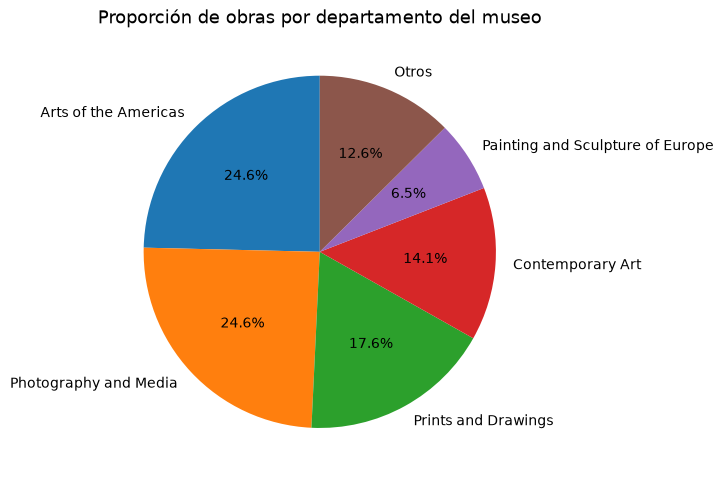

In [26]:
# Grafico 1 (obligatorio): torta con la proporcion de obras por departamento del museo
conteo_dep = df["department_title"].value_counts()

# Para que la torta sea legible: top 5 departamentos y el resto agrupado en "Otros"
top5 = conteo_dep.head(5)
otros = conteo_dep[5:].sum()
datos_torta = pd.concat([top5, pd.Series({"Otros": otros})]) if otros > 0 else top5

plt.figure(figsize=(7, 7))
plt.pie(datos_torta, labels=datos_torta.index, autopct="%1.1f%%", startangle=90)
plt.title("Proporción de obras por departamento del museo", fontsize=13)
plt.tight_layout()
plt.show()

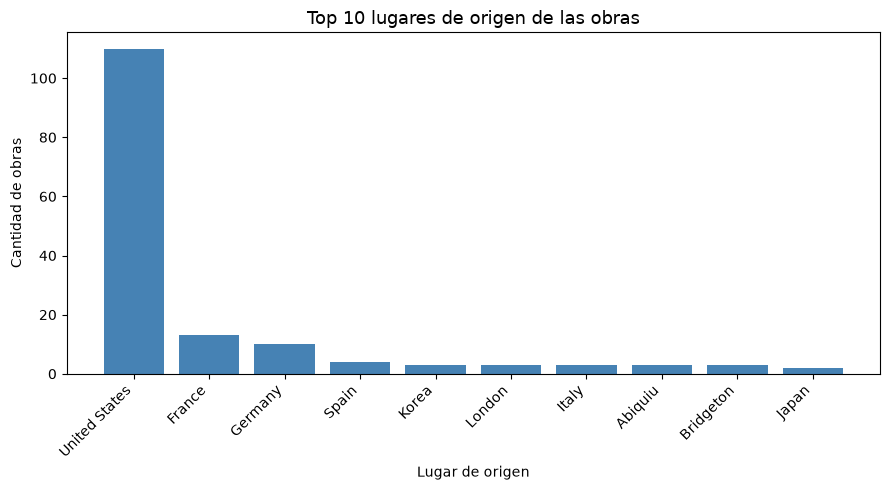

In [27]:
# Grafico 2: barras con los 10 lugares de origen con mas obras
top_lugares = df["place_of_origin"].value_counts().head(10)

plt.figure(figsize=(9, 5))
plt.bar(top_lugares.index, top_lugares.values, color="steelblue")
plt.title("Top 10 lugares de origen de las obras", fontsize=13)
plt.xlabel("Lugar de origen")
plt.ylabel("Cantidad de obras")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

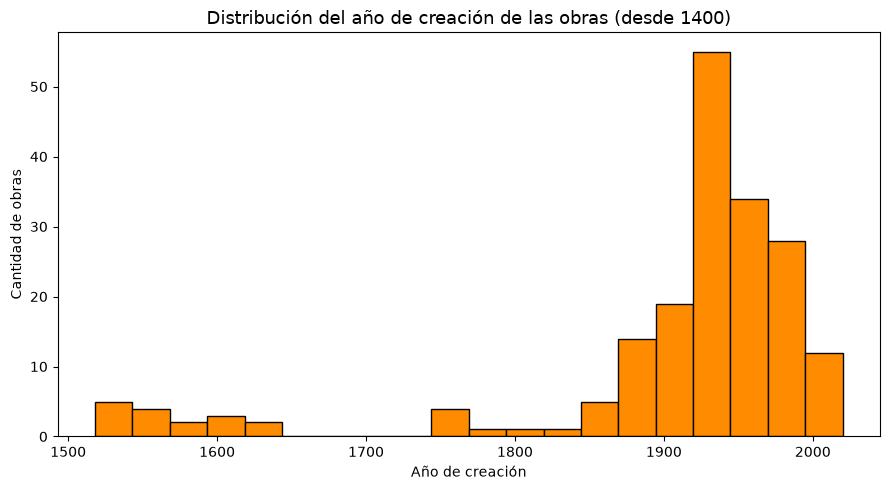

In [28]:
# Grafico 3: histograma de los anios de creacion
# Se filtra desde el anio 1400 para que el histograma sea legible:
# hay unas pocas piezas muy antiguas (la mas vieja del anio -883) que deformarian la escala.
anios = df.loc[df["date_start"] >= 1400, "date_start"]

plt.figure(figsize=(9, 5))
plt.hist(anios, bins=20, color="darkorange", edgecolor="black")
plt.title("Distribución del año de creación de las obras (desde 1400)", fontsize=13)
plt.xlabel("Año de creación")
plt.ylabel("Cantidad de obras")
plt.tight_layout()
plt.show()

## 6. Conclusiones

A partir de **200 obras** del Art Institute of Chicago se observa que la colección se
reparte principalmente entre tres departamentos: *Arts of the Americas* encabeza con
**49 obras (24.5% del total)**, prácticamente empatado con *Photography and Media*, y
les sigue *Prints and Drawings* con el 17.6%. **Estados Unidos** es, por mucho, el lugar
de origen más frecuente, con cerca de **110 obras**, muy por delante de Francia (13) y
Alemania (10). La artista con más piezas es **Georgia O'Keeffe**, con 18 obras.

En cuanto a la época, el año de creación promedio es **1857**, pero el rango es enorme:
va desde el año **883 a.C.** hasta **2020**. El histograma muestra que la gran mayoría de
las obras se crearon en el **siglo XX**, con un pico marcado entre 1920 y 1940.

Finalmente, solo **71 obras (35.5%)** son de dominio público y 129 no lo son, es decir que
cerca de dos terceras partes del material tiene restricciones de uso.